In [1]:
import pandas as pd
import numpy as np

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

## Load Training and Testing Datasets

In [2]:
# Load training and testing datasets
X_train = pd.read_csv("../dataset/processed/X_train.csv")
X_test = pd.read_csv("../dataset/processed/X_test.csv")

y_train = pd.read_csv("../dataset/processed/y_train.csv").squeeze("columns")
y_test = pd.read_csv("../dataset/processed/y_test.csv").squeeze("columns")

# Verify dataset dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (36168, 16)
Testing features: (9043, 16)
Training target: (36168,)
Testing target: (9043,)


## Define preprocessing pipelines

In [3]:
# Identify numerical and categorical features
categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Numerical preprocessing for Logistic Regression
numerical_pipeline_lr = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Numerical preprocessing for tree-based models
numerical_pipeline_tree = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Logistic Regression preprocessor
preprocessor_lr = ColumnTransformer(transformers=[
    ("num", numerical_pipeline_lr, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Random Forest preprocessor
preprocessor_rf = ColumnTransformer(transformers=[
    ("num", numerical_pipeline_tree, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Gradient Boosting preprocessor
preprocessor_gb = ColumnTransformer(transformers=[
    ("num", numerical_pipeline_tree, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

## Logistic Regression Model

In [4]:
# Create Logistic Regression pipeline
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor_lr),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [5]:
# Train Logistic Regression
lr_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [6]:
# Predict target classes
y_pred_lr = lr_model.predict(X_test)

# Predict subscription probabilities
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

In [7]:
# Calculate evaluation metrics
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, zero_division=0)
lr_roc_auc = roc_auc_score(y_test, y_prob_lr)

# Display evaluation results
print("Logistic Regression - Baseline Performance")
print("-------------------------------------------")
print(f"Accuracy:  {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall:    {lr_recall:.4f}")
print(f"F1-Score:  {lr_f1:.4f}")
print(f"ROC-AUC:   {lr_roc_auc:.4f}")

Logistic Regression - Baseline Performance
-------------------------------------------
Accuracy:  0.8935
Precision: 0.6678
Recall:    0.1786
F1-Score:  0.2819
ROC-AUC:   0.7717


In [8]:
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["No Subscription", "Subscription"]
))

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.90      0.99      0.94      7985
   Subscription       0.67      0.18      0.28      1058

       accuracy                           0.89      9043
      macro avg       0.78      0.58      0.61      9043
   weighted avg       0.87      0.89      0.87      9043



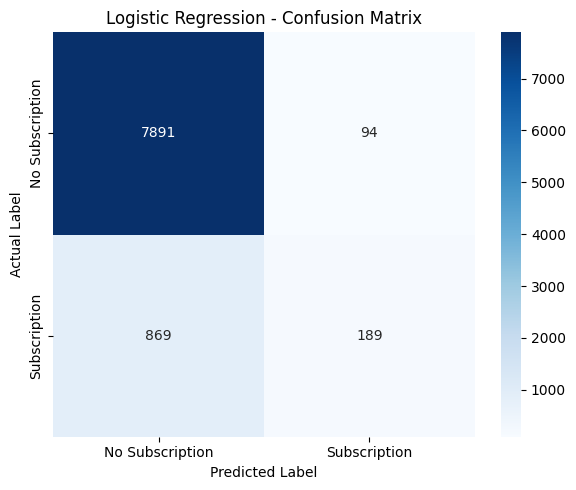

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Generate confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

# Visualise confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Subscription", "Subscription"],
    yticklabels=["No Subscription", "Subscription"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [10]:
# Store Logistic Regression baseline results
lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": lr_accuracy,
    "Precision": lr_precision,
    "Recall": lr_recall,
    "F1-Score": lr_f1,
    "ROC-AUC": lr_roc_auc
}

print(lr_results)

{'Model': 'Logistic Regression', 'Accuracy': 0.8935087913303107, 'Precision': 0.6678445229681979, 'Recall': 0.1786389413988658, 'F1-Score': 0.28187919463087246, 'ROC-AUC': 0.7717290098518844}


## Random Forest Model

In [11]:
# Create Random Forest baseline pipeline
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor_rf),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

In [12]:
# Train Random Forest
rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [13]:
# Predict target classes
y_pred_rf = rf_model.predict(X_test)

# Predict subscription probabilities
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

In [14]:
# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(
    y_test, y_pred_rf, zero_division=0
)

rf_recall = recall_score(
    y_test, y_pred_rf, zero_division=0
)

rf_f1 = f1_score(
    y_test, y_pred_rf, zero_division=0
)

rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

# Display results
print("Random Forest - Baseline Performance")
print("-------------------------------------")
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-Score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")

Random Forest - Baseline Performance
-------------------------------------
Accuracy:  0.8937
Precision: 0.6198
Recall:    0.2372
F1-Score:  0.3431
ROC-AUC:   0.7889


In [15]:
print("Random Forest - Classification Report")

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Subscription", "Subscription"]
))

Random Forest - Classification Report
                 precision    recall  f1-score   support

No Subscription       0.91      0.98      0.94      7985
   Subscription       0.62      0.24      0.34      1058

       accuracy                           0.89      9043
      macro avg       0.76      0.61      0.64      9043
   weighted avg       0.87      0.89      0.87      9043



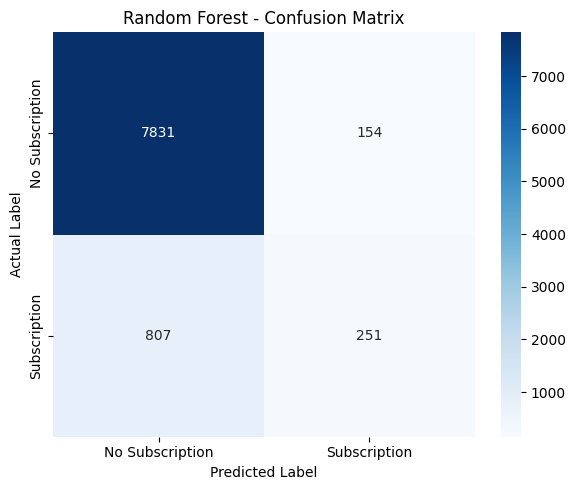

In [16]:
# Generate confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Subscription", "Subscription"],
    yticklabels=["No Subscription", "Subscription"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [17]:
# Store Random Forest baseline results
rf_results = {
    "Model": "Random Forest",
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1-Score": rf_f1,
    "ROC-AUC": rf_roc_auc
}

print(rf_results)

{'Model': 'Random Forest', 'Accuracy': 0.8937299568727193, 'Precision': 0.6197530864197531, 'Recall': 0.23724007561436672, 'F1-Score': 0.34313055365686945, 'ROC-AUC': 0.7888613219730283}


## Gradient Boosting Model

In [18]:
# Create Gradient Boosting baseline pipeline
gb_model = Pipeline(steps=[
    ("preprocessor", preprocessor_gb),
    ("classifier", GradientBoostingClassifier(
        random_state=42
    ))
])

In [19]:
# Train Gradient Boosting
gb_model.fit(X_train, y_train)

print("Gradient Boosting training completed.")

Gradient Boosting training completed.


In [20]:
# Predict target classes
y_pred_gb = gb_model.predict(X_test)

# Predict subscription probabilities
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

In [21]:
# Calculate evaluation metrics
gb_accuracy = accuracy_score(y_test, y_pred_gb)

gb_precision = precision_score(
    y_test, y_pred_gb, zero_division=0
)

gb_recall = recall_score(
    y_test, y_pred_gb, zero_division=0
)

gb_f1 = f1_score(
    y_test, y_pred_gb, zero_division=0
)

gb_roc_auc = roc_auc_score(y_test, y_prob_gb)

# Display results
print("Gradient Boosting - Baseline Performance")
print("----------------------------------------")
print(f"Accuracy:  {gb_accuracy:.4f}")
print(f"Precision: {gb_precision:.4f}")
print(f"Recall:    {gb_recall:.4f}")
print(f"F1-Score:  {gb_f1:.4f}")
print(f"ROC-AUC:   {gb_roc_auc:.4f}")

Gradient Boosting - Baseline Performance
----------------------------------------
Accuracy:  0.8937
Precision: 0.6520
Recall:    0.1966
F1-Score:  0.3021
ROC-AUC:   0.8027


In [22]:
print("Gradient Boosting - Classification Report")

print(classification_report(
    y_test,
    y_pred_gb,
    target_names=["No Subscription", "Subscription"]
))

Gradient Boosting - Classification Report
                 precision    recall  f1-score   support

No Subscription       0.90      0.99      0.94      7985
   Subscription       0.65      0.20      0.30      1058

       accuracy                           0.89      9043
      macro avg       0.78      0.59      0.62      9043
   weighted avg       0.87      0.89      0.87      9043



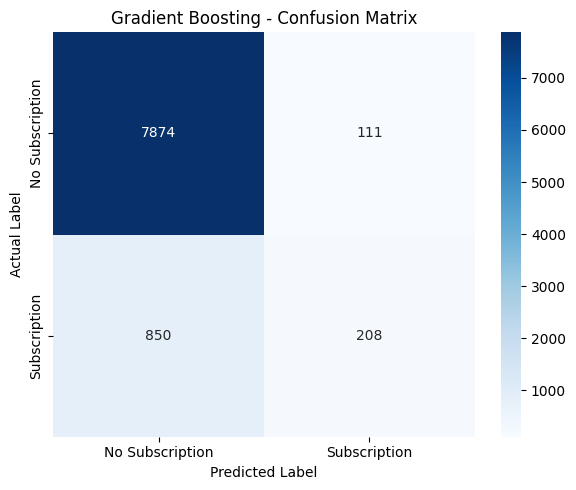

In [23]:
# Generate confusion matrix
cm_gb = confusion_matrix(y_test, y_pred_gb)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_gb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Subscription", "Subscription"],
    yticklabels=["No Subscription", "Subscription"]
)

plt.title("Gradient Boosting - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [24]:
# Store Gradient Boosting baseline results
gb_results = {
    "Model": "Gradient Boosting",
    "Accuracy": gb_accuracy,
    "Precision": gb_precision,
    "Recall": gb_recall,
    "F1-Score": gb_f1,
    "ROC-AUC": gb_roc_auc
}

print(gb_results)

{'Model': 'Gradient Boosting', 'Accuracy': 0.8937299568727193, 'Precision': 0.6520376175548589, 'Recall': 0.19659735349716445, 'F1-Score': 0.3021060275962237, 'ROC-AUC': 0.8027435657358493}


## Combined Results

In [25]:
# Combine baseline evaluation results
baseline_results = pd.DataFrame([
    lr_results,
    rf_results,
    gb_results
])

# Display comparison
baseline_results.set_index("Model").round(4)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8935,0.6678,0.1786,0.2819,0.7717
Random Forest,0.8937,0.6198,0.2372,0.3431,0.7889
Gradient Boosting,0.8937,0.6520,0.1966,0.3021,0.8027


## Hyperparameters Optimization

- Logistic Regression
- Random Forest
- Gradient Boosting

### Logistic Regression Optimization

In [26]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Configure 5-fold Stratified Cross-Validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [27]:
# Define Logistic Regression hyperparameter grid
lr_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"],
    "classifier__solver": ["lbfgs"]
}

# Configure GridSearchCV for Logistic Regression
lr_grid_search = GridSearchCV(
    estimator=lr_model,
    param_grid=lr_param_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    refit=True
)

In [28]:
# Perform hyperparameter optimisation
lr_grid_search.fit(X_train, y_train)

print("Logistic Regression optimisation completed.")

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Logistic Regression optimisation completed.


In [29]:
# Display the best hyperparameters
print("Best Parameters:")
print(lr_grid_search.best_params_)

# Display the best cross-validation F1-score
print("\nBest Cross-Validation F1-Score:")
print(round(lr_grid_search.best_score_, 4))

Best Parameters:
{'classifier__C': 10, 'classifier__class_weight': 'balanced', 'classifier__solver': 'lbfgs'}

Best Cross-Validation F1-Score:
0.3732


In [30]:
# Convert GridSearchCV results into a DataFrame
lr_cv_results = pd.DataFrame(lr_grid_search.cv_results_)

# Select important columns
lr_cv_results = lr_cv_results[
    [
        "param_classifier__C",
        "param_classifier__class_weight",
        "param_classifier__solver",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
]

# Sort by F1-score
lr_cv_results = lr_cv_results.sort_values(
    by="rank_test_score"
)

lr_cv_results

,param_classifier__C,param_classifier__class_weight,param_classifier__solver,mean_test_score,std_test_score,rank_test_score
7,10.00,balanced,lbfgs,0.373225,0.003066,1
5,1.00,balanced,lbfgs,0.373131,0.003602,2
9,100.00,balanced,lbfgs,0.372776,0.002959,3
3,0.10,balanced,lbfgs,0.371818,0.003638,4
1,0.01,balanced,lbfgs,0.366668,0.006355,5
8,100.00,None,lbfgs,0.275996,0.012798,6
6,10.00,None,lbfgs,0.275776,0.013217,7
4,1.00,None,lbfgs,0.275328,0.012909,8
2,0.10,None,lbfgs,0.266949,0.010348,9
0,0.01,None,lbfgs,0.219883,0.011409,10


In [31]:
# Retrieve the best Logistic Regression model
best_lr_model = lr_grid_search.best_estimator_

In [32]:
# Predict target classes
y_pred_lr_optimized = best_lr_model.predict(X_test)

# Predict subscription probabilities
y_prob_lr_optimized = best_lr_model.predict_proba(X_test)[:, 1]

In [33]:
# Evaluate optimised Logistic Regression
lr_optimized_results = {
    "Model": "Logistic Regression (Optimised)",
    "Accuracy": accuracy_score(y_test, y_pred_lr_optimized),
    "Precision": precision_score(
        y_test, y_pred_lr_optimized, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred_lr_optimized, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_pred_lr_optimized, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, y_prob_lr_optimized
    )
}

pd.DataFrame([lr_optimized_results]).set_index("Model").round(4)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression (Optimised),0.7558,0.267,0.6229,0.3738,0.7723


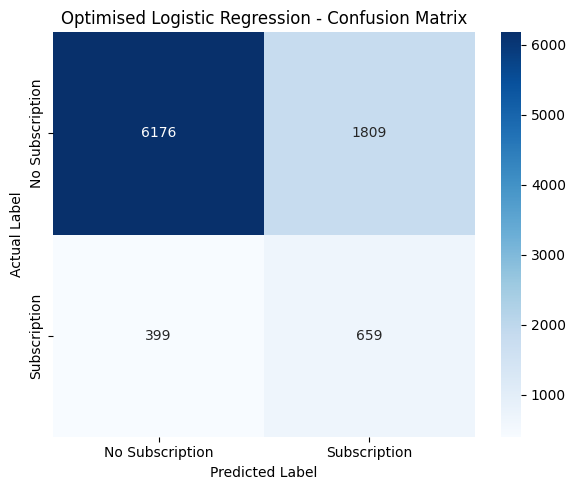

In [34]:
# Generate confusion matrix
cm_lr_optimized = confusion_matrix(
    y_test, y_pred_lr_optimized
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr_optimized,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Subscription", "Subscription"],
    yticklabels=["No Subscription", "Subscription"]
)

plt.title("Optimised Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [35]:
# Compare baseline and optimised Logistic Regression
lr_optimization_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression (Baseline)",
        "Accuracy": lr_accuracy,
        "Precision": lr_precision,
        "Recall": lr_recall,
        "F1-Score": lr_f1,
        "ROC-AUC": lr_roc_auc
    },
    lr_optimized_results
])

lr_optimization_comparison.set_index("Model").round(4)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression (Baseline),0.8935,0.6678,0.1786,0.2819,0.7717
Logistic Regression (Optimised),0.7558,0.2670,0.6229,0.3738,0.7723


In [ ]:
# Store logistic regression optimisation results
lr_optimized_results = {
    "Model": "Logistic Regression (Optimised)",
    "Best Parameters": lr_grid_search.best_params_,
    "CV F1-Score": lr_grid_search.best_score_,
    "Accuracy": accuracy_score(y_test, y_pred_lr_optimized),
    "Precision": precision_score(
        y_test, y_pred_lr_optimized, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred_lr_optimized, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_pred_lr_optimized, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, y_prob_lr_optimized
    )
}

### Random Forest Optimization

In [37]:
# Define Random Forest hyperparameter grid
rf_param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__class_weight": [None, "balanced"]
}

In [38]:
# Configure GridSearchCV for Random Forest
rf_grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    refit=True
)

In [39]:
# Perform Random Forest hyperparameter optimisation
rf_grid_search.fit(X_train, y_train)

print("Random Forest optimisation completed.")

Fitting 5 folds for each of 162 candidates, totalling 810 fits
Random Forest optimisation completed.


In [40]:
# Display the best hyperparameters
print("Best Parameters:")
print(rf_grid_search.best_params_)

# Display the best cross-validation F1-score
print("\nBest Cross-Validation F1-Score:")
print(round(rf_grid_search.best_score_, 4))

Best Parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 4, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 300}

Best Cross-Validation F1-Score:
0.4742


In [41]:
# Convert GridSearchCV results into a DataFrame
rf_cv_results = pd.DataFrame(rf_grid_search.cv_results_)

# Select relevant columns
rf_cv_results = rf_cv_results[
    [
        "param_classifier__n_estimators",
        "param_classifier__max_depth",
        "param_classifier__min_samples_split",
        "param_classifier__min_samples_leaf",
        "param_classifier__class_weight",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
]

# Sort configurations by ranking
rf_cv_results = rf_cv_results.sort_values(
    by="rank_test_score"
)

rf_cv_results.head(15)

,param_classifier__n_estimators,param_classifier__max_depth,param_classifier__min_samples_split,param_classifier__min_samples_leaf,param_classifier__class_weight,mean_test_score,std_test_score,rank_test_score
107,300,None,10,4,balanced,0.474182,0.009829,1
105,100,None,10,4,balanced,0.473796,0.010625,2
106,200,None,10,4,balanced,0.472568,0.009021,3
101,300,None,2,4,balanced,0.472010,0.010435,4
104,300,None,5,4,balanced,0.472010,0.010435,4
100,200,None,2,4,balanced,0.471500,0.012237,6
103,200,None,5,4,balanced,0.471500,0.012237,6
99,100,None,2,4,balanced,0.470847,0.011294,8
102,100,None,5,4,balanced,0.470847,0.011294,8
155,300,20,2,4,balanced,0.469770,0.007694,10


In [43]:
# Retrieve the best Random Forest model
best_rf_model = rf_grid_search.best_estimator_

# Predict target classes
y_pred_rf_optimized = best_rf_model.predict(X_test)

# Predict subscription probabilities
y_prob_rf_optimized = best_rf_model.predict_proba(X_test)[:, 1]

In [44]:
# Evaluate optimised Random Forest
rf_optimized_results = {
    "Model": "Random Forest (Optimised)",

    "Accuracy": accuracy_score(
        y_test, y_pred_rf_optimized
    ),

    "Precision": precision_score(
        y_test, y_pred_rf_optimized, zero_division=0
    ),

    "Recall": recall_score(
        y_test, y_pred_rf_optimized, zero_division=0
    ),

    "F1-Score": f1_score(
        y_test, y_pred_rf_optimized, zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_test, y_prob_rf_optimized
    )
}

pd.DataFrame([rf_optimized_results]).set_index("Model").round(4)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Random Forest (Optimised),0.8706,0.453,0.5104,0.48,0.8044


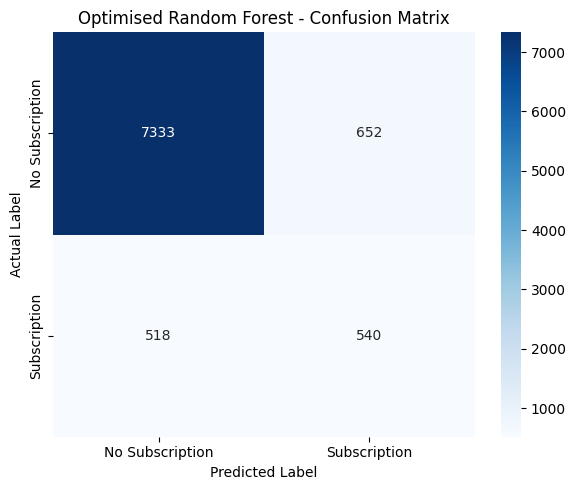

In [45]:
# Generate confusion matrix
cm_rf_optimized = confusion_matrix(
    y_test,
    y_pred_rf_optimized
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf_optimized,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Subscription", "Subscription"],
    yticklabels=["No Subscription", "Subscription"]
)

plt.title("Optimised Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [46]:
# Compare baseline and optimised Random Forest
rf_optimization_comparison = pd.DataFrame([
    {
        "Model": "Random Forest (Baseline)",
        "Accuracy": rf_accuracy,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1-Score": rf_f1,
        "ROC-AUC": rf_roc_auc
    },
    rf_optimized_results
])

rf_optimization_comparison.set_index("Model").round(4)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Random Forest (Baseline),0.8937,0.6198,0.2372,0.3431,0.7889
Random Forest (Optimised),0.8706,0.4530,0.5104,0.4800,0.8044


In [ ]:
# Store random forest optimisation results
rf_optimized_results = {
    "Model": "Random Forest (Optimised)",
    "Best Parameters": rf_grid_search.best_params_,
    "CV F1-Score": rf_grid_search.best_score_,
    "Accuracy": accuracy_score(y_test, y_pred_rf_optimized),
    "Precision": precision_score(
        y_test, y_pred_rf_optimized, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred_rf_optimized, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_pred_rf_optimized, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, y_prob_rf_optimized
    )
}